<div dir="rtl" style="text-align: right;">
<h3>1 کتابخانه‌ها و نمودار</h3>
</div>

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from scipy import stats
from sqlalchemy import create_engine, text
from statsmodels.stats.proportion import proportions_ztest

pio.templates.default = 'plotly_dark'
pio.renderers.default = 'notebook'
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', '{:.3f}'.format)

ROOT = Path.cwd().parent
load_dotenv(ROOT / '.env')

True

<div dir="rtl" style="text-align: right;">
<h3>1.1 آزمون فرض</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h2>2. خواندن داده‌ها</h2>
</div>

<div dir="rtl" style="text-align: right;">
<h2>3. پاک‌سازی داده‌ها</h2>
<h3>3.1 داده های خالی</h3>

</div>

<div dir="rtl" style="text-align: right;">
<h3>3.2 داده‌های پرت</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h3>3.3 بازیکنان واجد شرایط و فعال</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h2>4. شناخت داده‌ها</h2>
<h3>4.1 ویژگی‌های بدنی</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h4>بارگذاری و آماده‌سازی داده‌ها</h4>
</div>

In [2]:
DATA_DIR = Path(os.getenv('DATA_DIR', ROOT / 'scraper' / 'output'))
SEASONS = ['2019-20', '2020-21', '2021-22', '2022-23', '2023-24']
sns.set_theme(style='whitegrid', palette='deep')


def read_all(name):
    return pd.concat([pd.read_csv(DATA_DIR / s / f'{name}.csv') for s in SEASONS], ignore_index=True)


def keep_combined(df):
    df = df.assign(combined=df.team.str.contains('TM|TOT', na=False))
    df = df.sort_values('combined', ascending=False)
    return df.drop_duplicates(['season', 'player_name']).drop(columns='combined')


rosters = read_all('rosters').drop_duplicates(['season', 'player_name'])
adv = keep_combined(read_all('advanced_regular'))
tot = keep_combined(read_all('totals_regular'))
mvp = read_all('mvp_voting')

feet_inch = rosters.height_feet_inches.str.split('-', expand=True).astype(int)
rosters['height_cm'] = (feet_inch[0] * 12 + feet_inch[1]) * 2.54
rosters['weight_kg'] = rosters.weight_pounds * 0.4536
rosters['bmi'] = rosters.weight_kg / (rosters.height_cm / 100) ** 2
rosters['experience'] = rosters.experience.replace('R', 0).astype(int)
rosters['is_us'] = rosters.birth_country.str.startswith('us')

players = adv[['season', 'player_name', 'team', 'age', 'minutes_played']].merge(
    rosters[['season', 'player_name', 'height_cm', 'weight_kg', 'bmi', 'experience', 'is_us']],
    on=['season', 'player_name'], how='left')
players['position'] = adv.set_index(['season', 'player_name']).position.reindex(
    pd.MultiIndex.from_frame(players[['season', 'player_name']])).values
print(players.shape, players.isna().sum().sum())
players.head()

(2785, 11) 0


,season,player_name,team,age,minutes_played,height_cm,weight_kg,bmi,experience,is_us,position
0,2020-21,JJ Redick,2TM,36,723,190.500,90.720,24.998,14,True,SG
1,2023-24,Seth Curry,2TM,33,616,185.420,83.916,24.408,9,True,SG
2,2019-20,Jeff Green,2TM,33,960,203.200,106.596,25.816,11,True,C
3,2022-23,Goran Dragić,2TM,36,870,193.040,86.184,23.128,14,False,PG
4,2021-22,Mac McClung,2TM,23,25,187.960,83.916,23.753,0,True,SG


<div dir="rtl" style="text-align: right;">
<h4>تابع آمار توصیفی</h4>
</div>

In [3]:
def describe(df, cols, labels=None):
    rows = []
    for c in cols:
        x = df[c].dropna()
        q1, q3 = x.quantile([.25, .75])
        iqr = q3 - q1
        rows.append({
            'variable': (labels or {}).get(c, c), 'n': len(x), 'mean': x.mean(), 'median': x.median(),
            'std': x.std(), 'min': x.min(), 'q1': q1, 'q3': q3, 'max': x.max(),
            'cv': x.std() / x.mean() if x.mean() else np.nan, 'skew': x.skew(), 'kurtosis': x.kurt(),
            'outliers': int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()),
            'normaltest_p': stats.normaltest(x).pvalue,
        })
    return pd.DataFrame(rows).set_index('variable')


def hist_grid(df, cols, labels=None, ncols=3, color='#4c72b0'):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.8 * nrows))
    for ax, c in zip(np.ravel(axes), cols):
        x = df[c].dropna()
        sns.histplot(x, kde=True, ax=ax, color=color, edgecolor='white')
        ax.axvline(x.mean(), color='crimson', ls='--', lw=1.3, label='mean')
        ax.axvline(x.median(), color='gold', ls='-', lw=1.3, label='median')
        ax.set_title((labels or {}).get(c, c))
        ax.set_xlabel('')
        ax.legend(fontsize=8)
    for ax in np.ravel(axes)[len(cols):]:
        ax.axis('off')
    fig.tight_layout()
    plt.show()


def box_grid(df, cols, labels=None, ncols=3, color='#55a868'):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 2.6 * nrows))
    for ax, c in zip(np.ravel(axes), cols):
        sns.boxplot(x=df[c].dropna(), ax=ax, color=color, fliersize=3)
        ax.set_title((labels or {}).get(c, c))
        ax.set_xlabel('')
    for ax in np.ravel(axes)[len(cols):]:
        ax.axis('off')
    fig.tight_layout()
    plt.show()


def qq_grid(df, cols, labels=None, ncols=3):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
    for ax, c in zip(np.ravel(axes), cols):
        stats.probplot(df[c].dropna(), dist='norm', plot=ax)
        ax.set_title((labels or {}).get(c, c))
        ax.get_lines()[0].set_markersize(3)
    for ax in np.ravel(axes)[len(cols):]:
        ax.axis('off')
    fig.tight_layout()
    plt.show()

<div dir="rtl" style="text-align: right;">
<h4>آمار توصیفی ویژگی‌های بدنی</h4>
</div>

In [4]:
body_cols = ['height_cm', 'weight_kg', 'bmi', 'age', 'experience']
body_labels = {'height_cm': 'Height (cm)', 'weight_kg': 'Weight (kg)', 'bmi': 'BMI',
               'age': 'Age (years)', 'experience': 'Experience (seasons)'}
describe(players, body_cols, body_labels)

,n,mean,median,std,min,q1,q3,max,cv,skew,kurtosis,outliers,normaltest_p
variable,,,,,,,,,,,,,
Height (cm),2785,198.883,198.120,8.352,170.180,193.040,205.740,228.600,0.042,0.012,-0.143,6,0.261
Weight (kg),2785,98.170,97.524,11.073,72.576,90.720,105.689,141.070,0.113,0.398,-0.062,22,0.000
BMI,2785,24.773,24.846,1.808,18.932,23.658,25.886,32.820,0.073,0.117,0.576,51,0.000
Age (years),2785,25.671,25.000,4.171,19.000,23.000,28.000,43.000,0.162,0.732,0.079,53,0.000
Experience (seasons),2785,4.092,3.000,4.029,0.000,1.000,6.000,21.000,0.985,1.146,0.747,94,0.000


<div dir="rtl" style="text-align: right;">
<h4>هیستوگرام و نمودار چگالی</h4>
</div>

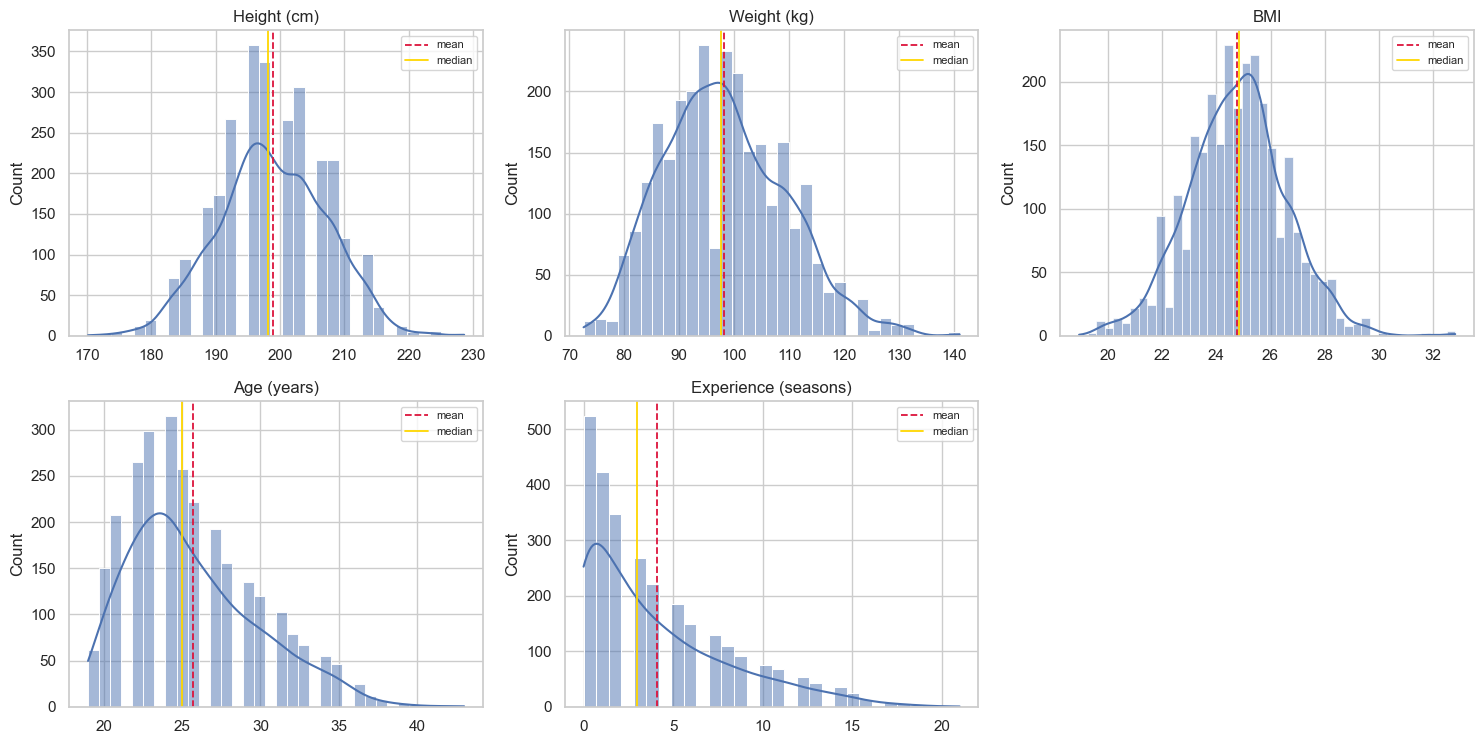

In [5]:
hist_grid(players, body_cols, body_labels)

<div dir="rtl" style="text-align: right;">
<h4>نمودار جعبه‌ای</h4>
</div>

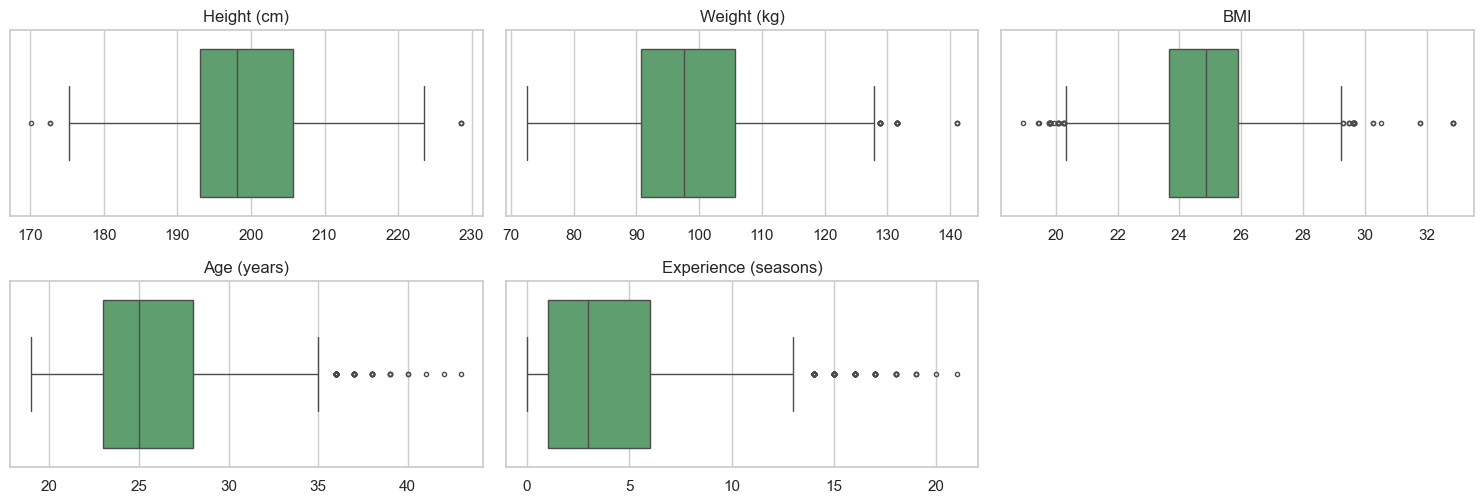

In [6]:
box_grid(players, body_cols, body_labels)

<div dir="rtl" style="text-align: right;">
<h4>نمودار Q-Q</h4>
</div>

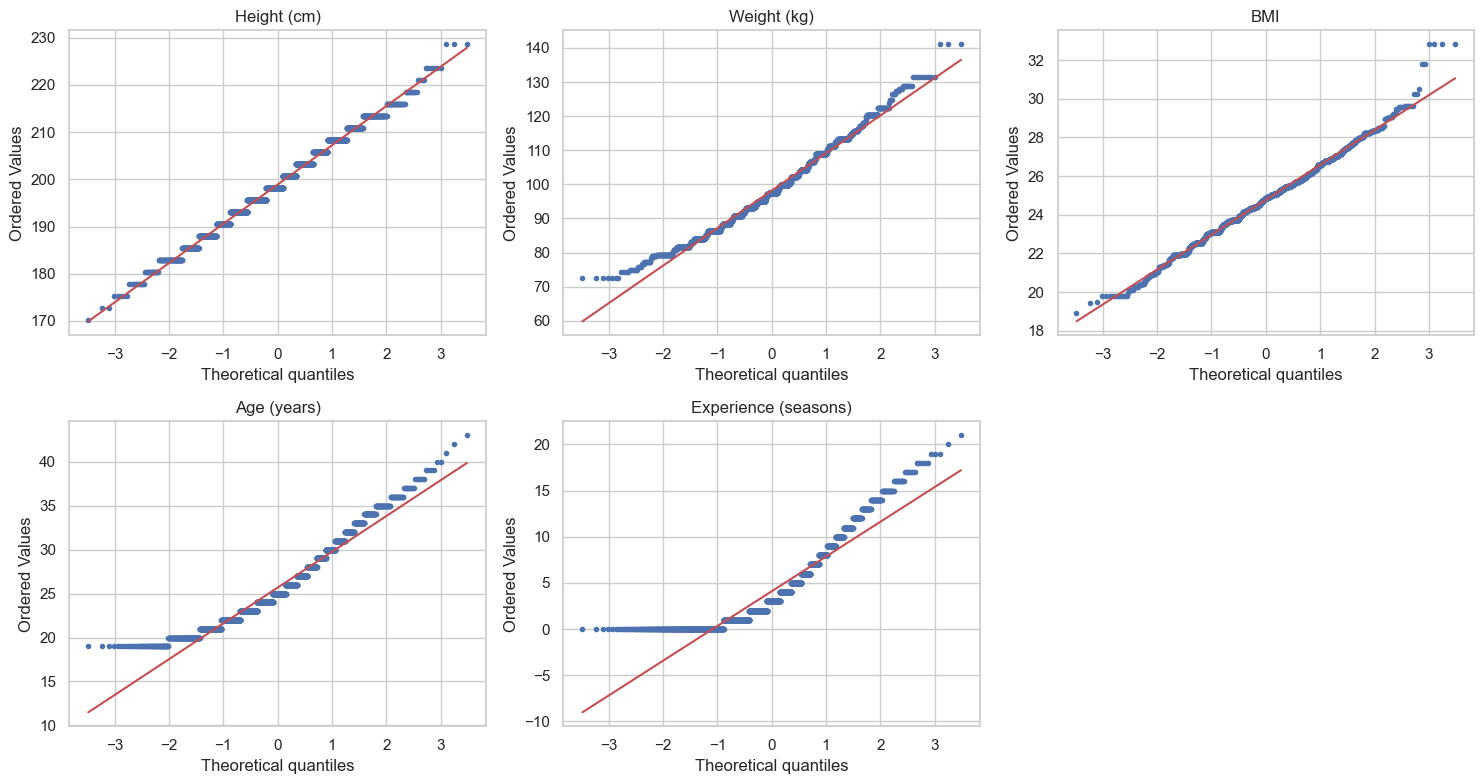

In [7]:
qq_grid(players, body_cols, body_labels)

<div dir="rtl" style="text-align: right;">
<p>قد تنها متغیری است که نرمال می‌ماند (چولگی ۰٫۰۱ و p-value برابر ۰٫۲۶). وزن کمی راست‌چوله است و سن و سابقه راست‌چوله‌اند، چون بازیکن جوان زیاد و بازیکن باتجربه کم داریم. آزمون نرمال‌بودن برای بقیه رد می‌شود.</p>
</div>

<div dir="rtl" style="text-align: right;">
<h4>متغیرهای دسته‌ای: پست و کشور تولد</h4>
</div>

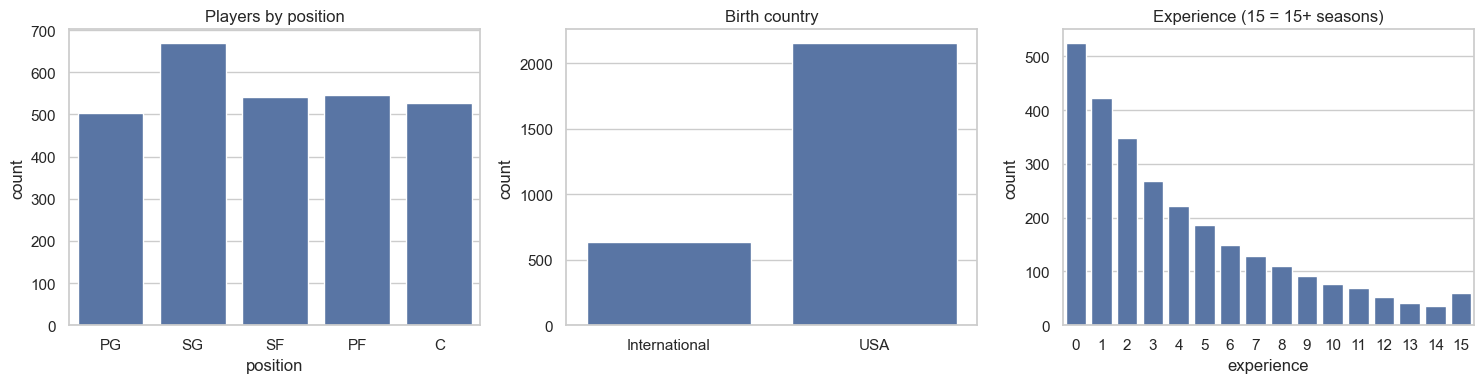

position
SG   0.240
PF   0.196
SF   0.194
C    0.189
PG   0.181
Name: proportion, dtype: float64

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
order = ['PG', 'SG', 'SF', 'PF', 'C']
sns.countplot(x='position', data=players, order=order, ax=axes[0])
axes[0].set_title('Players by position')
sns.countplot(x='is_us', data=players, ax=axes[1])
axes[1].set_xticks([0, 1], ['International', 'USA'])
axes[1].set_xlabel('')
axes[1].set_title('Birth country')
sns.countplot(x='experience', data=players.assign(experience=players.experience.clip(upper=15)), ax=axes[2])
axes[2].set_title('Experience (15 = 15+ seasons)')
fig.tight_layout()
plt.show()
players.position.value_counts(normalize=True).round(3)

<div dir="rtl" style="text-align: right;">
<h4>قد بازیکنان در پنج فصل</h4>
</div>

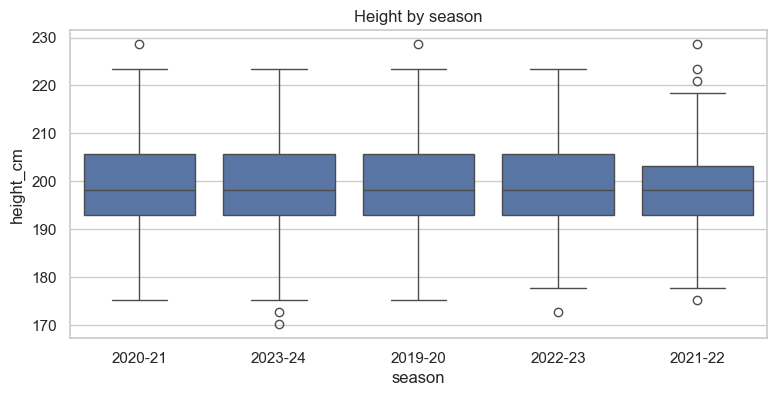

,count,mean,median,std
season,,,,
2019-20,529,198.930,198.120,8.610
2020-21,540,198.890,198.120,8.520
2021-22,605,198.400,198.120,8.390
2022-23,539,199.100,198.120,8.130
2023-24,572,199.150,198.120,8.130


In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(x='season', y='height_cm', data=players, ax=ax, color='#4c72b0')
ax.set_title('Height by season')
plt.show()
players.groupby('season').height_cm.agg(['count', 'mean', 'median', 'std']).round(2)

<div dir="rtl" style="text-align: right;">
<p>میانگین قد در هر پنج فصل بین ۱۹۸٫۴ تا ۱۹۹٫۲ سانتی‌متر است، پس می‌شود فصل‌ها را برای تحلیل قد با هم ادغام کرد.</p>
</div>

<div dir="rtl" style="text-align: right;">
<h3>4.2 عملکرد بازیکنان</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h4>آماده‌سازی آمار عملکرد</h4>
</div>

In [10]:
perf = adv.merge(tot[['season', 'player_name', 'team', 'points', 'total_rebounds', 'assists',
                      'steals', 'blocks', 'games_played']],
                 on=['season', 'player_name', 'team'], suffixes=('', '_t'))
for col, new in [('points', 'ppg'), ('total_rebounds', 'rpg'), ('assists', 'apg'),
                 ('steals', 'spg'), ('blocks', 'bpg')]:
    perf[new] = perf[col] / perf.games_played
perf['mpg'] = perf.minutes_played / perf.games_played
perf_labels = {'mpg': 'Minutes per game', 'ppg': 'Points per game', 'rpg': 'Rebounds per game',
               'apg': 'Assists per game', 'spg': 'Steals per game', 'bpg': 'Blocks per game',
               'player_efficiency_rating': 'PER', 'true_shooting_percentage': 'TS%',
               'usage_percentage': 'USG%', 'win_shares': 'Win Shares',
               'win_shares_per_48_minutes': 'WS/48', 'box_plus_minus': 'BPM',
               'value_over_replacement_player': 'VORP'}
perf_cols = list(perf_labels)
perf.shape

(2785, 43)

<div dir="rtl" style="text-align: right;">
<h4>توزیع دقیقه بازی و فیلتر ۱۰۰۰ دقیقه</h4>
</div>

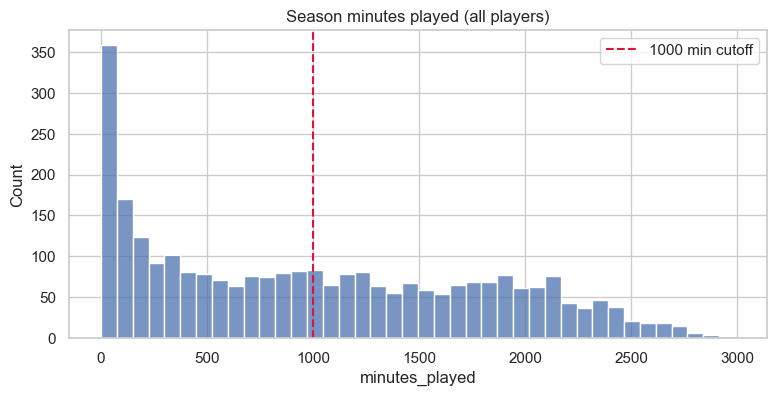

2785 1298 0.466


In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(perf.minutes_played, bins=40, ax=ax, color='#4c72b0', edgecolor='white')
ax.axvline(1000, color='crimson', ls='--', label='1000 min cutoff')
ax.set_title('Season minutes played (all players)')
ax.legend()
plt.show()
qualified = perf[perf.minutes_played >= 1000]
print(len(perf), len(qualified), round(len(qualified) / len(perf), 3))

<div dir="rtl" style="text-align: right;">
<h4>آمار توصیفی عملکرد (بازیکنان با حداقل ۱۰۰۰ دقیقه)</h4>
</div>

In [12]:
describe(qualified, perf_cols, perf_labels)

,n,mean,median,std,min,q1,q3,max,cv,skew,kurtosis,outliers,normaltest_p
variable,,,,,,,,,,,,,
Minutes per game,1298,27.125,27.680,5.754,13.944,22.418,32.042,37.912,0.212,-0.205,-1.020,0,0.000
Points per game,1298,13.352,11.704,6.229,3.420,8.596,17.194,34.692,0.467,0.877,0.139,14,0.000
Rebounds per game,1298,4.918,4.321,2.445,0.833,3.200,5.971,15.158,0.497,1.251,1.493,63,0.000
Assists per game,1298,2.994,2.338,2.019,0.312,1.457,4.100,11.738,0.674,1.275,1.397,33,0.000
Steals per game,1298,0.849,0.800,0.340,0.169,0.598,1.047,2.161,0.401,0.801,0.648,26,0.000
Blocks per game,1298,0.531,0.405,0.451,0.000,0.238,0.660,3.577,0.850,2.292,7.340,78,0.000
PER,1298,15.327,14.700,4.514,3.700,12.000,17.900,34.100,0.294,0.849,0.871,25,0.000
TS%,1298,0.578,0.575,0.047,0.430,0.546,0.605,0.745,0.082,0.390,0.508,24,0.000
USG%,1298,20.060,19.200,5.789,6.500,15.800,23.775,39.600,0.289,0.566,-0.123,11,0.000


<div dir="rtl" style="text-align: right;">
<h4>هیستوگرام و نمودار چگالی</h4>
</div>

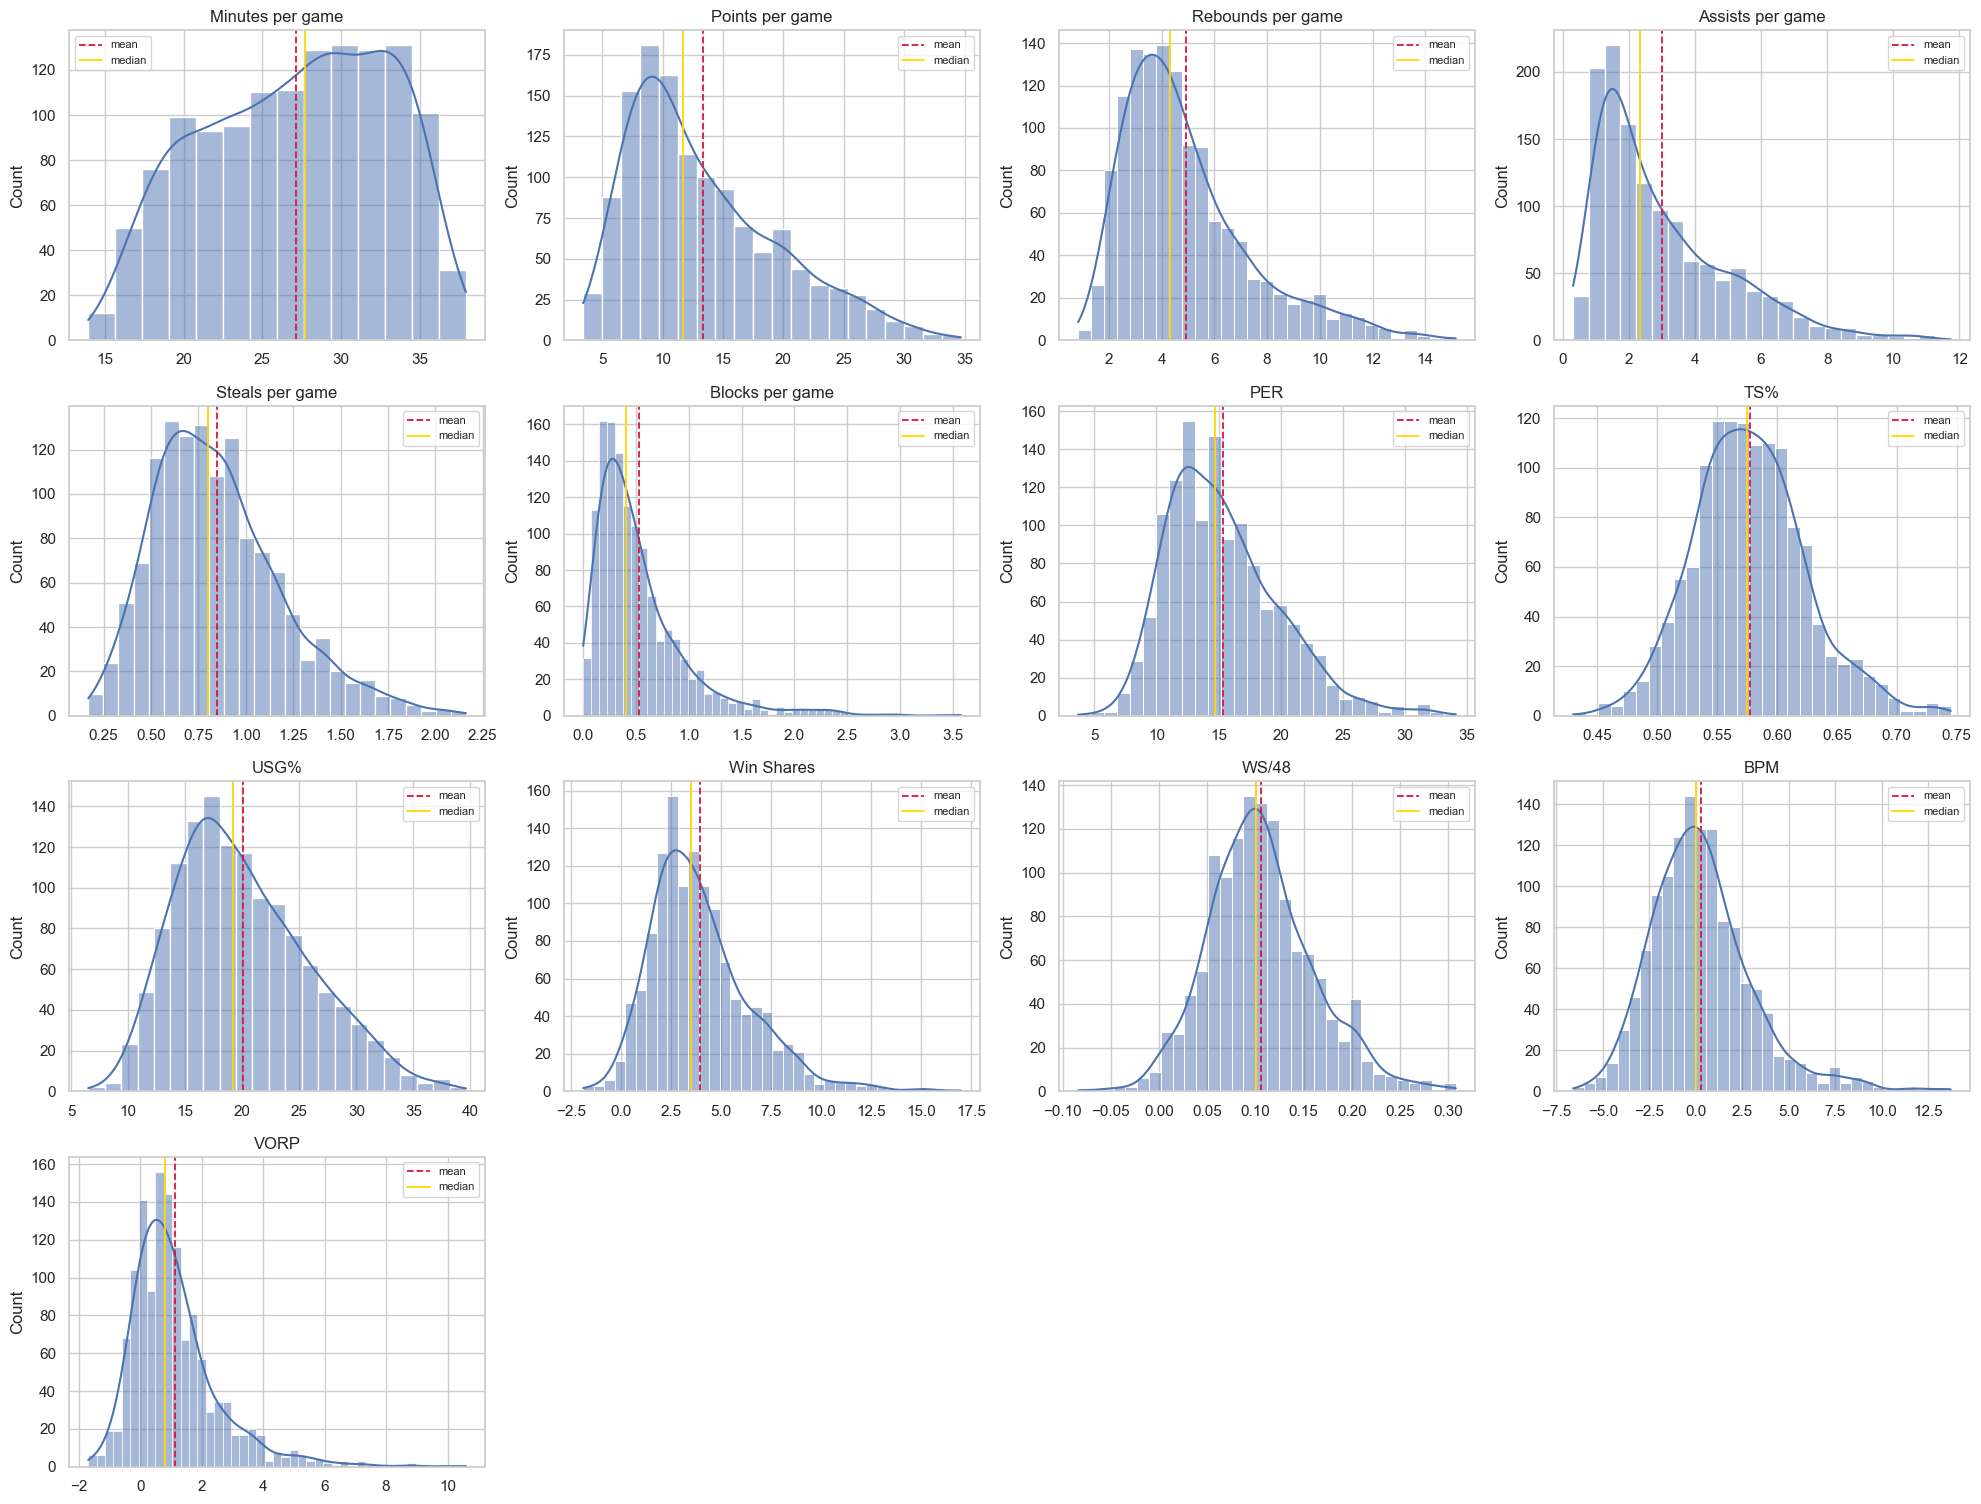

In [13]:
hist_grid(qualified, perf_cols, perf_labels, ncols=4)

<div dir="rtl" style="text-align: right;">
<h4>نمودار جعبه‌ای</h4>
</div>

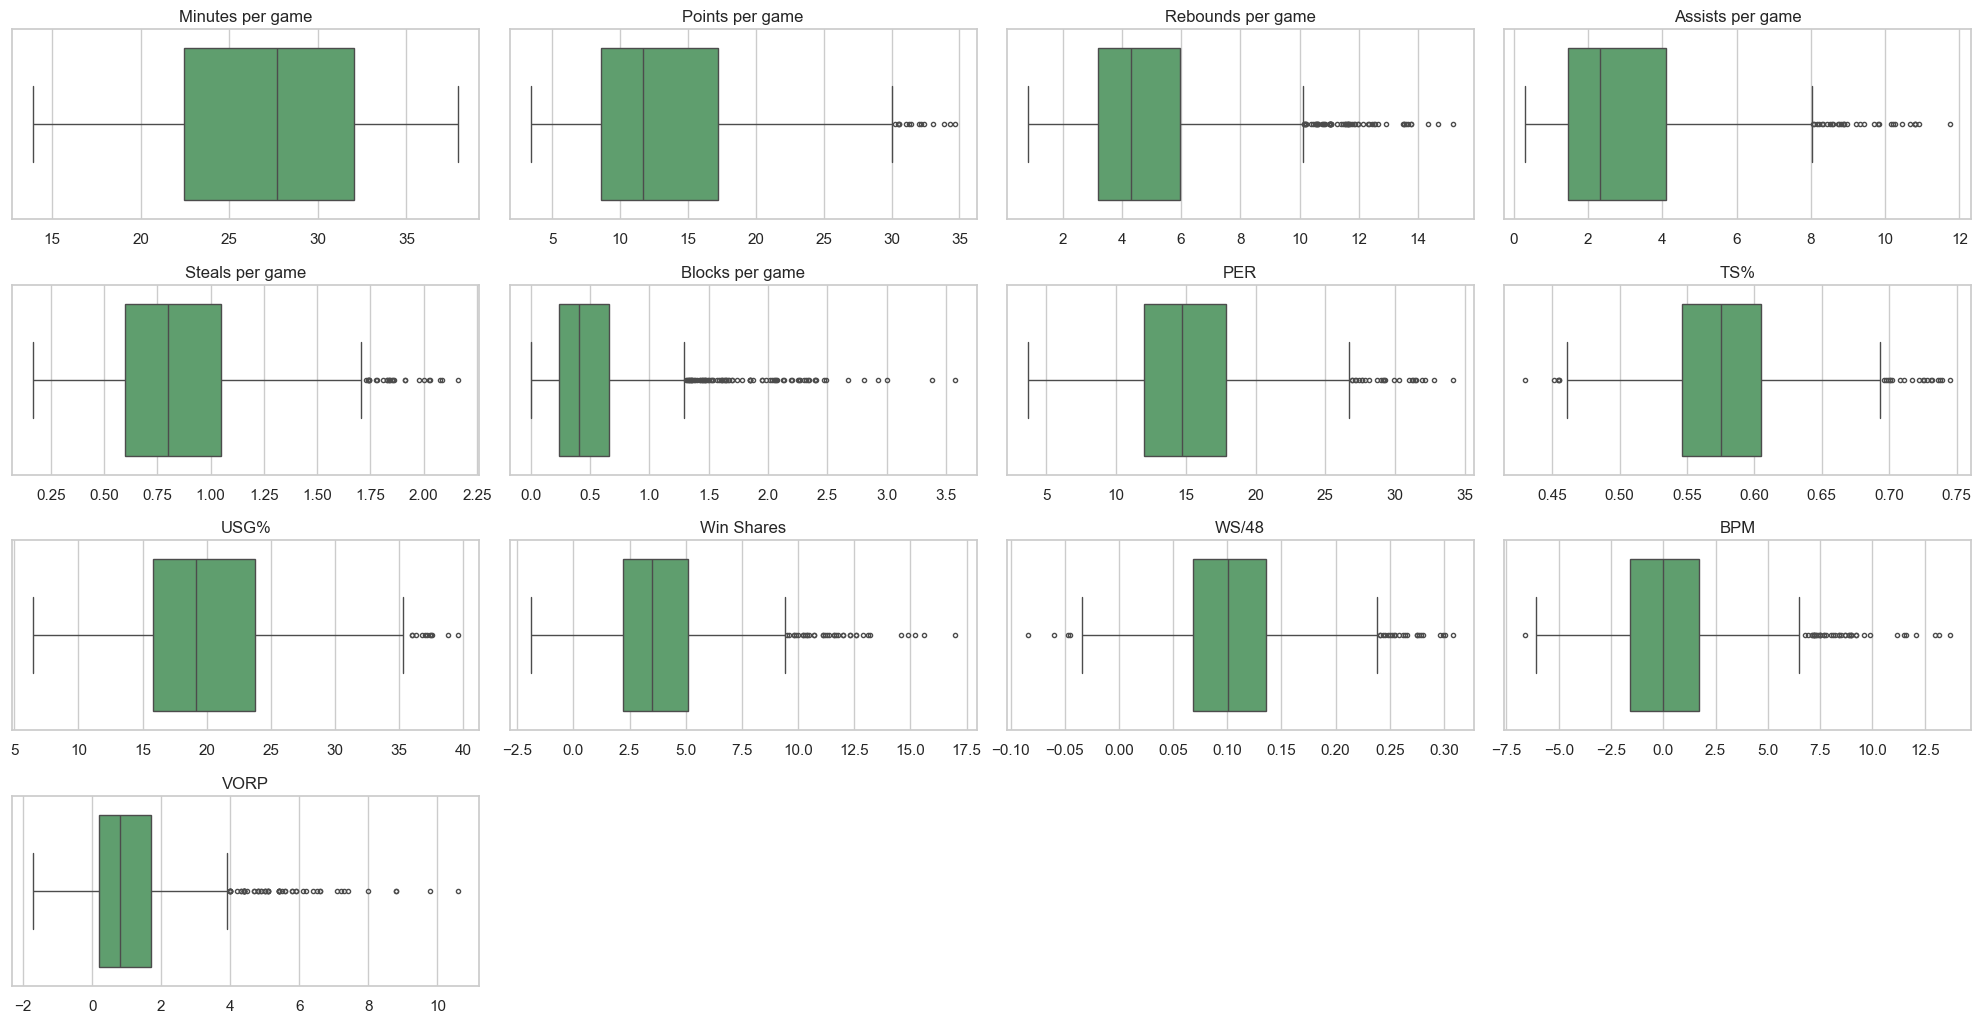

In [14]:
box_grid(qualified, perf_cols, perf_labels, ncols=4)

<div dir="rtl" style="text-align: right;">
<h4>چولگی متغیرها</h4>
</div>

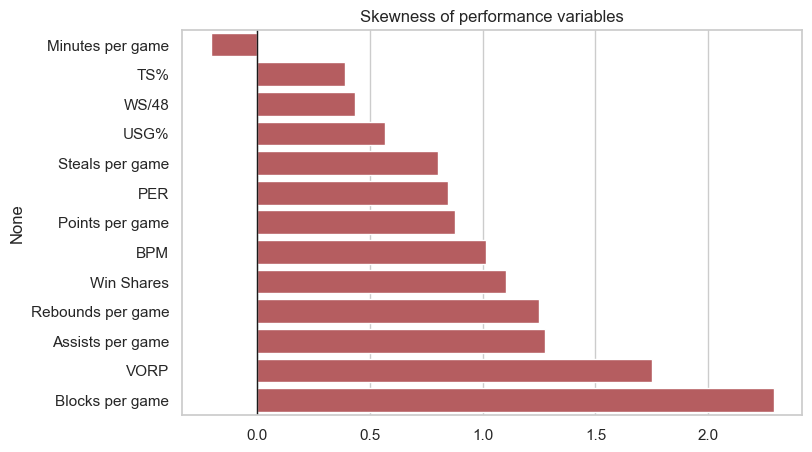

In [15]:
skew = qualified[perf_cols].skew().rename(index=perf_labels).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=skew.values, y=skew.index, ax=ax, color='#c44e52')
ax.axvline(0, color='k', lw=1)
ax.set_title('Skewness of performance variables')
plt.show()

<div dir="rtl" style="text-align: right;">
<p>آمار شمارشی (امتیاز، ریباند، پاس، بلاک) راست‌چوله است، چون چند ستاره در دم راست هستند. بلاک بیشترین چولگی (۲٫۳) را دارد. دقیقه بازی و TS% تقریباً قرینه‌اند. فقط حدود ۴۷٪ بازیکن‌ها حداقل ۱۰۰۰ دقیقه بازی کرده‌اند.</p>
</div>

<div dir="rtl" style="text-align: right;">
<h3>4.3 تیم‌ها و قهرمانان</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h3>4.4 رابطه میان آمار بازیکنان</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h3>4.5 مقایسه پست‌ها در پنج فصل</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h2>5. معیار انتخاب بازیکنان برتر</h2>
</div>

<div dir="rtl" style="text-align: right;">
<h2>6. آمار توصیفی</h2>
<h3>6.1 قد نامزدهای MVP و بازیکنان برتر</h3>
</div>

In [16]:
import nba_top_players

<div dir="rtl" style="text-align: right;">
<h4>۵۰ بازیکن برتر هر فصل و نامزدهای MVP</h4>
</div>

In [17]:
engine = create_engine(os.getenv('DB_URL'))
heights = players[['season', 'player_name', 'height_cm', 'position']]

top50 = pd.concat([nba_top_players.get_top_players(engine, s) for s in SEASONS], ignore_index=True)
top50 = top50[['season', 'player_name']].merge(heights, on=['season', 'player_name'], how='left')
mvp_c = mvp[['season', 'player_name']].merge(heights, on=['season', 'player_name'], how='left')
mvp_c['in_top50'] = mvp_c.set_index(['season', 'player_name']).index.isin(
    top50.set_index(['season', 'player_name']).index)
print(len(top50), len(mvp_c), top50.height_cm.isna().sum(), mvp_c.height_cm.isna().sum())
print('MVP candidates also in top 50:', mvp_c.in_top50.mean().round(3))
mvp_c.groupby('season').size()

250 61 0 0
MVP candidates also in top 50: 0.951


season
2019-20    12
2020-21    15
2021-22    12
2022-23    13
2023-24     9
dtype: int64

<div dir="rtl" style="text-align: right;">
<h4>آمار توصیفی قد دو گروه</h4>
</div>

In [18]:
groups = {'MVP candidates': mvp_c.height_cm, 'Top 50': top50.height_cm}
pd.DataFrame({k: v.describe() for k, v in groups.items()}).T.assign(
    skew=[v.skew() for v in groups.values()])

,count,mean,std,min,25%,50%,75%,max,skew
MVP candidates,61.000,200.702,9.453,182.880,193.040,203.200,210.820,215.900,-0.342
Top 50,250.000,202.550,9.435,182.880,195.580,204.470,210.820,218.440,-0.475


<div dir="rtl" style="text-align: right;">
<h4>توزیع قد: چگالی، جعبه‌ای و ECDF</h4>
</div>

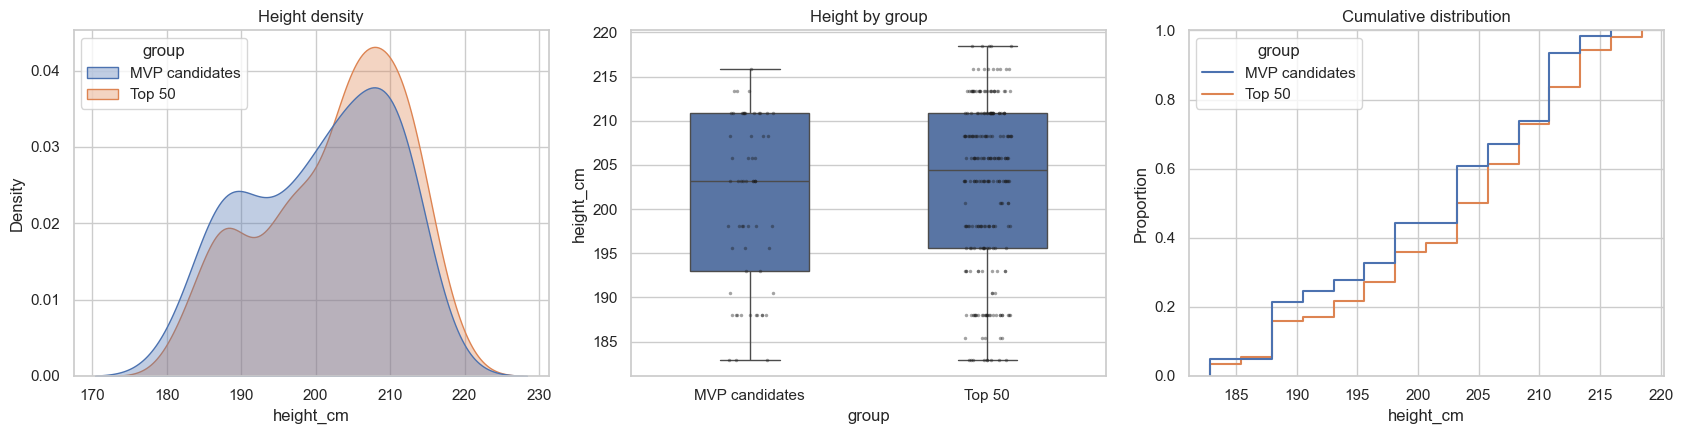

In [19]:
both = pd.concat([mvp_c.assign(group='MVP candidates'), top50.assign(group='Top 50')])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.kdeplot(data=both, x='height_cm', hue='group', common_norm=False, fill=True, alpha=.35, ax=axes[0])
axes[0].set_title('Height density')
sns.boxplot(data=both, x='group', y='height_cm', ax=axes[1], width=.5)
sns.stripplot(data=both, x='group', y='height_cm', ax=axes[1], color='k', size=2.5, alpha=.4)
axes[1].set_title('Height by group')
sns.ecdfplot(data=both, x='height_cm', hue='group', ax=axes[2])
axes[2].set_title('Cumulative distribution')
fig.tight_layout()
plt.show()

<div dir="rtl" style="text-align: right;">
<h4>آزمون‌های آماری</h4>
</div>

In [20]:
a, b = mvp_c.height_cm.dropna(), top50.height_cm.dropna()
print('Shapiro MVP candidates p =', round(stats.shapiro(a).pvalue, 4))
print('Shapiro Top 50 p =', round(stats.shapiro(b).pvalue, 4))
print('Levene p =', round(stats.levene(a, b).pvalue, 4))
t = stats.ttest_ind(a, b, equal_var=False)
u = stats.mannwhitneyu(a, b, alternative='two-sided')
pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
rng = np.random.default_rng(42)
boot = [rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(10000)]
print('Welch t =', round(t.statistic, 3), 'p =', round(t.pvalue, 4))
print('Mann-Whitney p =', round(u.pvalue, 4))
print("Cohen's d =", round((a.mean() - b.mean()) / pooled, 3))
print('Mean difference (cm) =', round(a.mean() - b.mean(), 2),
      '95% bootstrap CI =', np.percentile(boot, [2.5, 97.5]).round(2))

Shapiro MVP candidates p = 0.0006
Shapiro Top 50 p = 0.0
Levene p = 0.854


Welch t = -1.37 p = 0.1742
Mann-Whitney p = 0.18
Cohen's d = -0.196
Mean difference (cm) = -1.85 95% bootstrap CI = [-4.51  0.68]


<div dir="rtl" style="text-align: right;">
<p>نامزدهای MVP به‌طور میانگین ۱٫۹ سانتی‌متر کوتاه‌ترند (۲۰۰٫۷ در برابر ۲۰۲٫۶)، ولی این تفاوت کوچک است (d حدود ۰٫۲) و معنادار نیست (p حدود ۰٫۱۷). بازه ۹۵٪ بوت‌استرپ هم صفر را شامل می‌شود.</p>
</div>

<div dir="rtl" style="text-align: right;">
<h4>بررسی پایداری: گروه‌های مستقل و بازیکنان یکتا</h4>
</div>

In [21]:
top_only = top50.merge(mvp_c[['season', 'player_name']], on=['season', 'player_name'],
                       how='left', indicator=True).query("_merge == 'left_only'")
rows = []
for name, x, y in [('Top 50 without MVP candidates', mvp_c.height_cm.dropna(), top_only.height_cm.dropna()),
                   ('Unique players', mvp_c.drop_duplicates('player_name').height_cm.dropna(),
                    top50.drop_duplicates('player_name').height_cm.dropna())]:
    rows.append({'comparison': name, 'n_mvp': len(x), 'n_other': len(y),
                 'diff_cm': x.mean() - y.mean(),
                 'welch_p': stats.ttest_ind(x, y, equal_var=False).pvalue,
                 'mannwhitney_p': stats.mannwhitneyu(x, y).pvalue})
pd.DataFrame(rows).set_index('comparison')

,n_mvp,n_other,diff_cm,welch_p,mannwhitney_p
comparison,,,,,
Top 50 without MVP candidates,61,192,-2.326,0.097,0.102
Unique players,29,106,-2.991,0.133,0.137


<div dir="rtl" style="text-align: right;">
<h4>ترکیب پست‌ها در دو گروه</h4>
</div>

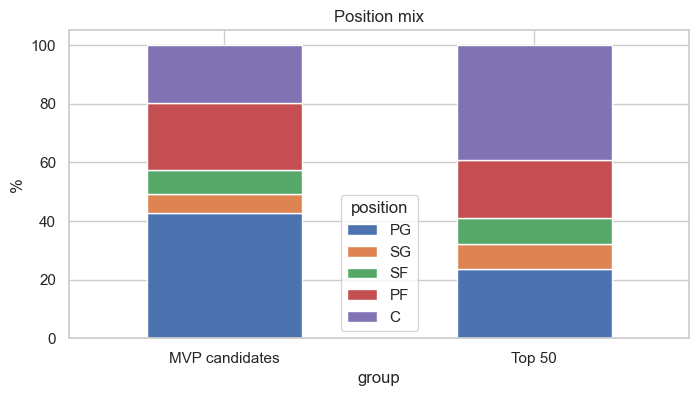

position           PG    SG    SF     PF      C
group                                          
MVP candidates 42.600 6.600 8.200 23.000 19.700
Top 50         23.600 8.400 9.200 19.600 39.200
Chi-square p = 0.0152


group,MVP candidates,Top 50
position,,
PG,193.900,191.600
SG,193.000,191.800
SF,200.200,200.400
PF,206.800,206.200
C,211.000,210.100


In [22]:
order = ['PG', 'SG', 'SF', 'PF', 'C']
pos = pd.crosstab(both.group, both.position)[order]
pos.div(pos.sum(axis=1), axis=0).mul(100).round(1).plot(kind='bar', stacked=True, figsize=(8, 4), rot=0)
plt.ylabel('%')
plt.title('Position mix')
plt.show()
print(pos.div(pos.sum(axis=1), axis=0).mul(100).round(1))
print('Chi-square p =', round(stats.chi2_contingency(pos)[1], 4))
both.groupby(['position', 'group']).height_cm.mean().unstack().loc[order].round(1)

<div dir="rtl" style="text-align: right;">
<p>ترکیب پست‌ها فرق دارد (p حدود ۰٫۰۱۵): ۴۳٪ نامزدها پوینت‌گارد هستند، ولی در ۵۰ نفر برتر فقط ۲۴٪. سنترها ۳۹٪ ۵۰ نفر برتر هستند. قد در هر پست در دو گروه تقریباً برابر است، پس اختلاف کوچک بالا از ترکیب پست‌ها می‌آید.</p>
</div>

<div dir="rtl" style="text-align: right;">
<h3>6.2 تجربه و قد بازیکنان تیم قهرمان</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h3>6.3 پیشنهاد پوینت‌گارد</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h2>7. آزمون فرض</h2>
<h3>7.1 تغییر چابکی بازیکنان برتر</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h3>7.2 تجربه بازیکنان تیم قهرمان</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h2>8. تحلیل‌های تکمیلی</h2>
<h3>8.1 تحلیل تکمیلی اول</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h3>8.2 تحلیل تکمیلی دوم</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h3>8.3 تحلیل تکمیلی سوم</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h3>8.4 تحلیل تکمیلی چهارم</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h3>8.5 تحلیل تکمیلی پنجم</h3>
</div>